In [9]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
os.chdir("/content/drive/MyDrive/part_c_diffusion")
sys.path.append(os.getcwd())

!pip install -q diffusers

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!apt-get -qq install p7zip-full p7zip-rar
!7z x /content/drive/MyDrive/uhat.rar -o/content/uhat_data -y

Selecting previously unselected package 7zip-rar.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../7zip-rar_23.01-4_amd64.deb ...
Unpacking 7zip-rar (23.01-4) ...
Selecting previously unselected package p7zip-rar.
Preparing to unpack .../p7zip-rar_16.02+transitional.1_all.deb ...
Unpacking p7zip-rar (16.02+transitional.1) ...
Setting up 7zip-rar (23.01-4) ...
Setting up p7zip-rar (16.02+transitional.1) ...

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/                                 1 file, 37052281 bytes (36 MiB)

Extracting archive: /content/drive/MyDrive/uhat.rar
  0% 256 Open              11% 6144 Open              --
Path = /content/drive/MyDrive/uhat.rar
Type = Rar5
Physi

In [3]:
# 2. Load data, build model, run the checks
import torch
from data import get_data
from model import build_unet
from diffusion import DEVICE, alpha_bar

loader, images, class_names = get_data(
    data_dir="/content/uhat_data/uhat"
)
unet = build_unet(DEVICE)

print("alpha_bar[0], alpha_bar[-1]:", alpha_bar[0].item(), alpha_bar[-1].item())  # ~1, ~4e-5
x0, y = next(iter(loader))
print("data range:", x0.min().item(), x0.max().item(), "| label dtype:", y.dtype)

x = torch.randn(8, 1, 28, 28, device=DEVICE)
t = torch.randint(0, 1000, (8,), device=DEVICE).long()
yy = torch.randint(0, 40, (8,), device=DEVICE).long()
print("U-Net output:", unet(x, t, class_labels=yy).sample.shape)                  # (8,1,28,28)
print("Parameters:", sum(p.numel() for p in unet.parameters()))

keys in npz: ['x_chars_train', 'x_digits_train', 'x_chars_test', 'x_digits_test', 'y_chars_train', 'y_digits_train', 'y_chars_test', 'y_digits_test']
images: torch.Size([28328, 1, 28, 28]) range: -1.0 1.0
labels: 0 to 39
alpha_bar[0], alpha_bar[-1]: 0.9998999834060669 4.035829260828905e-05
data range: -1.0 1.0 | label dtype: torch.int64
U-Net output: torch.Size([8, 1, 28, 28])
Parameters: 4028353


Resumed from epoch 2
Epoch 3/40  loss 0.0462  time 2.8 min
Epoch 4/40  loss 0.0392  time 3.7 min
Epoch 5/40  loss 0.0349  time 4.7 min
Epoch 6/40  loss 0.0330  time 5.6 min
Epoch 7/40  loss 0.0312  time 6.5 min
Epoch 8/40  loss 0.0304  time 7.5 min
Epoch 9/40  loss 0.0295  time 8.4 min
Epoch 10/40  loss 0.0284  time 9.4 min
Epoch 11/40  loss 0.0278  time 10.3 min
Epoch 12/40  loss 0.0279  time 11.3 min
Epoch 13/40  loss 0.0276  time 12.2 min
Epoch 14/40  loss 0.0274  time 13.2 min
Epoch 15/40  loss 0.0271  time 14.1 min
Epoch 16/40  loss 0.0263  time 15.0 min
Epoch 17/40  loss 0.0266  time 16.0 min
Epoch 18/40  loss 0.0265  time 16.9 min
Epoch 19/40  loss 0.0259  time 17.9 min
Epoch 20/40  loss 0.0250  time 18.8 min
Epoch 21/40  loss 0.0248  time 19.8 min
Epoch 22/40  loss 0.0246  time 20.7 min
Epoch 23/40  loss 0.0245  time 21.7 min
Epoch 24/40  loss 0.0247  time 22.6 min
Epoch 25/40  loss 0.0248  time 23.5 min
Epoch 26/40  loss 0.0245  time 24.5 min
Epoch 27/40  loss 0.0239  time 25.

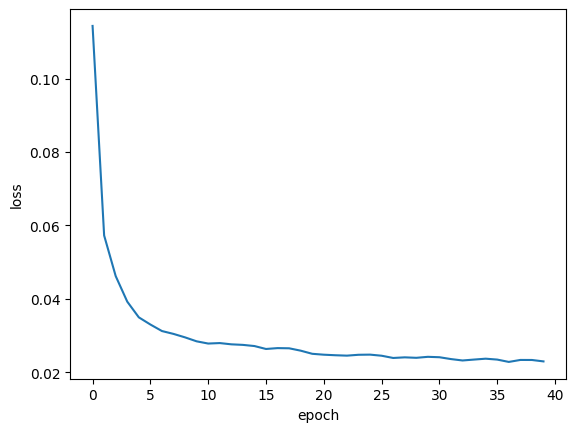

Final loss: 0.022938100323248823 | GPU: Tesla T4 | minutes: 37.68321973880132


In [ ]:
# 3. Train (try epochs=2 first, then 40)
from train import train
train(unet, loader, epochs=40, ckpt_path="/content/drive/MyDrive/part_c_ddpm.pt")

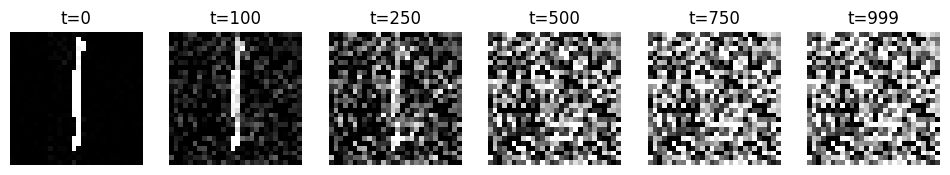

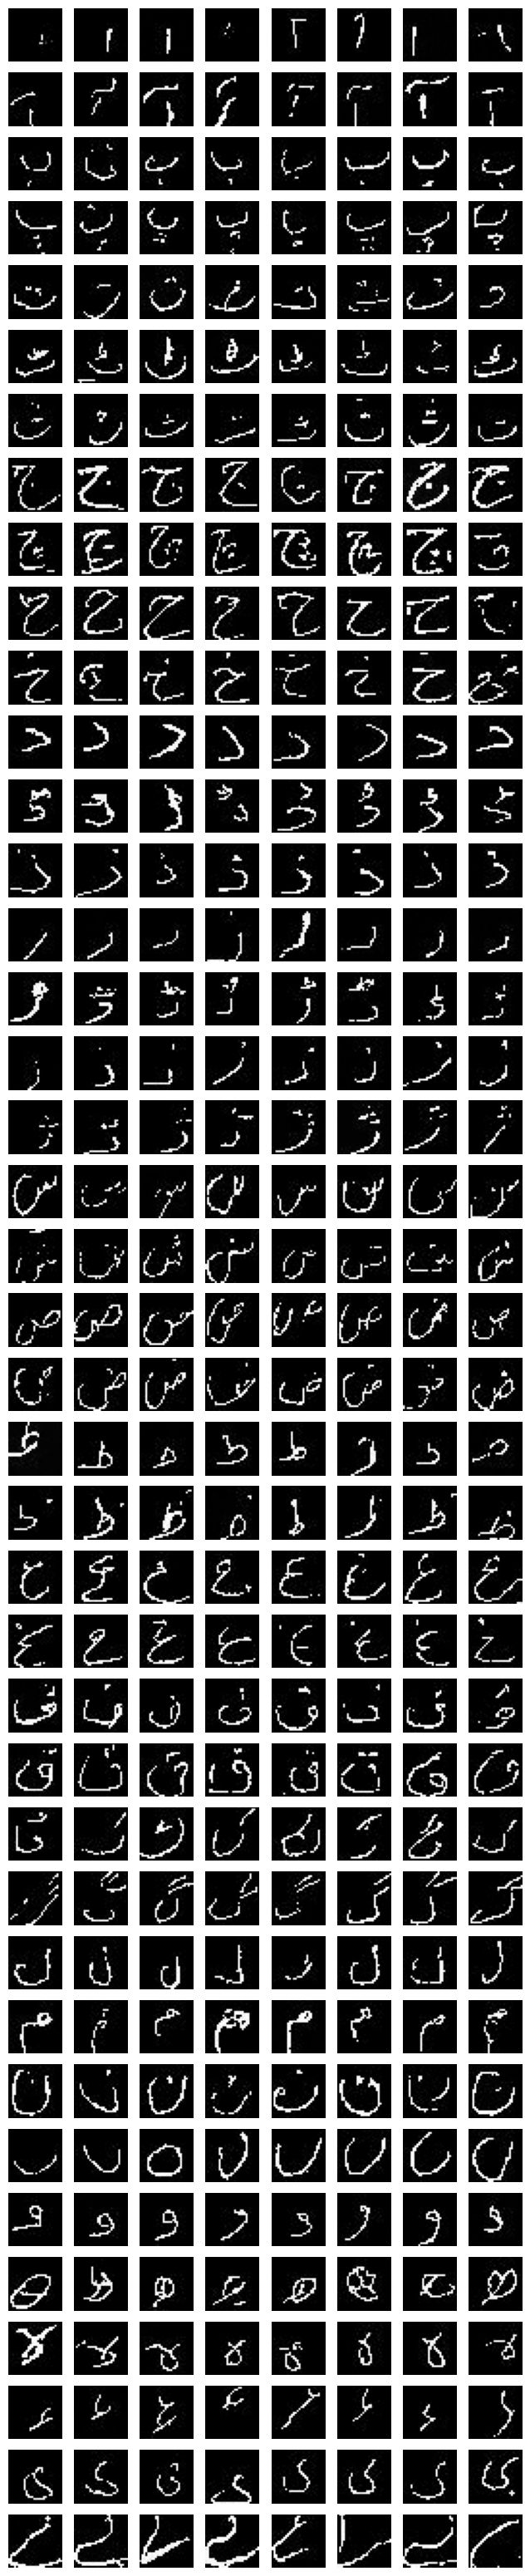

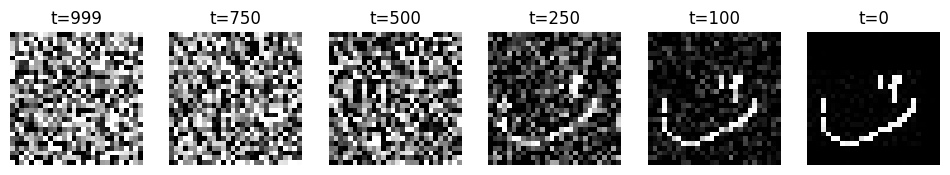

In [ ]:
# 4. Figures
from evaluate import forward_figure, grid_figure, denoising_figure
forward_figure(images)
grid_figure(unet, class_names)
denoising_figure(unet, class_id=5)

In [5]:
import torch
from diffusion import DEVICE

ck = torch.load("/content/drive/MyDrive/part_c_ddpm.pt", map_location=DEVICE)
unet.load_state_dict(ck["model"])
unet.eval()
print("Loaded epoch:", ck["epoch"])      # should say 40

Loaded epoch: 40


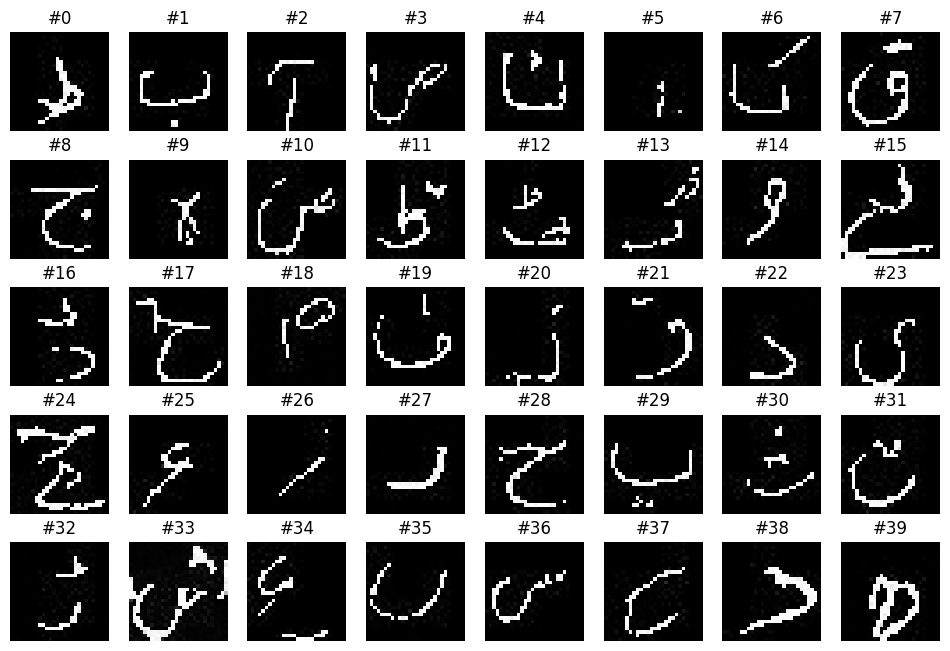

In [12]:
# make the sheet (run once, before members guess)
from evaluate import make_eval_sheet
make_eval_sheet(unet, class_names)

In [13]:
# score (run after the CSV is filled)
import importlib, evaluate
importlib.reload(evaluate)
from evaluate import score_eval
score_eval("results/human_eval.csv")

Member 1: 12.50% | Member 2: 10.00% | Agreement: 75.00%
